# 实验三 C：基于特征通道选择的模型表征能力分析

使用 ImageNet 预训练 ResNet-18，在最后卷积阶段 `layer4` 输出上屏蔽通道，比较随机保留、高响应优先和低响应优先三种策略。随机策略重复 5 次，不重新训练模型。

固定使用 100 个不同类别的示例，其中包含前两项实验的五张图片，每类仅有一张示例。结果只反映这批示例上的变化，不能代表完整 ImageNet 测试集的性能。

数据来源：[图片仓库](https://github.com/EliSchwartz/imagenet-sample-images)；[类别索引](https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json)。首次运行需联网。

In [1]:
from pathlib import Path
from urllib.request import urlretrieve, urlopen
from concurrent.futures import ThreadPoolExecutor
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision.models import resnet18, ResNet18_Weights

ROOT = Path.cwd()
if ROOT.name != "exp3" and (ROOT / "exp3").is_dir():
    ROOT = ROOT / "exp3"
DATA_DIR = ROOT / "data" / "channel_samples"
CACHE_DIR = ROOT / ".cache" / "channel_samples"
RESULT_DIR = ROOT / "results" / "exp3C"
for folder in [DATA_DIR, CACHE_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(ROOT / ".cache" / "torch"))
SEED = 42
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("运行设备：", device)

运行设备： cpu


## 1. 准备固定样本

固定保留金鱼、金毛犬、虎斑猫、客机和校车，使用种子 42 从其余类别中随机选取 95 类。根据图片文件名的 WordNet ID 获取类别编号，不用文件顺序猜测标签。已有图片直接复用，其他图片下载到本地。

In [2]:
def load_json(url, filename):
    path = CACHE_DIR / filename
    if not path.exists():
        with urlopen(url, timeout=60) as response:
            data = json.load(response)
        path.write_text(json.dumps(data), encoding="utf-8")
    return json.loads(path.read_text(encoding="utf-8"))

class_index = load_json(
    "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json",
    "class_index.json")
tree = load_json(
    "https://api.github.com/repos/EliSchwartz/imagenet-sample-images/git/trees/master?recursive=1",
    "image_tree.json")
filename_by_id = {item["path"].split("_")[0]: item["path"]
                  for item in tree["tree"] if item["path"].endswith(".JPEG")}
fixed_ids = [1, 207, 281, 404, 779]
rng = np.random.default_rng(SEED)
remaining = np.setdiff1d(np.arange(1000), fixed_ids)
selected_ids = sorted(fixed_ids + rng.choice(remaining, 95, replace=False).tolist())
manifest = pd.DataFrame([
    {"class_id": i, "synset": class_index[str(i)][0],
     "filename": filename_by_id[class_index[str(i)][0]]}
    for i in selected_ids
])
assert len(manifest) == 100 and manifest["class_id"].nunique() == 100
manifest.to_csv(DATA_DIR / "manifest.csv", index=False)

base_url = "https://raw.githubusercontent.com/EliSchwartz/imagenet-sample-images/master/"
def get_image(filename):
    previous = ROOT / "data" / "gradcam_samples" / filename
    path = previous if previous.exists() else DATA_DIR / filename
    if not path.exists():
        temporary = path.with_suffix(".download")
        urlretrieve(base_url + filename, temporary)
        temporary.replace(path)
    with Image.open(path) as image:
        image.verify()
    return path

with ThreadPoolExecutor(max_workers=4) as pool:
    image_paths = []
    for index, path in enumerate(pool.map(get_image, manifest["filename"]), start=1):
        image_paths.append(path)
        if index % 20 == 0:
            print(f"图片已准备：{index}/100")

图片已准备：20/100


图片已准备：40/100


图片已准备：60/100


图片已准备：80/100


图片已准备：100/100


## 2. 提取特征并建立基线

目标位置为 `layer4` 输出，即全局平均池化之前的 512 个通道。保留的通道数值不变，屏蔽的通道置零，不进行额外缩放。

后续只有全局平均池化和全连接层，因此先池化再乘通道掩码，与先屏蔽整个特征图再池化完全等价。只提取一次完整特征，即可快速比较不同掩码，下面也对这一等价性进行数值核验。

In [3]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()
preprocess = weights.transforms()
class_names = weights.meta["categories"]
backbone = torch.nn.Sequential(*list(model.children())[:-2])
BATCH_SIZE = 16
pooled_batches = []

with torch.no_grad():
    for start in range(0, len(image_paths), BATCH_SIZE):
        tensors = []
        for path in image_paths[start:start + BATCH_SIZE]:
            with Image.open(path) as image:
                tensors.append(preprocess(image.convert("RGB")))
        inputs = torch.stack(tensors).to(device)
        features = backbone(inputs)
        pooled_batches.append(model.avgpool(features).flatten(1))
        if start == 0:
            example_feature = features[:1].clone()
            mean = torch.tensor(preprocess.mean).view(3, 1, 1)
            std = torch.tensor(preprocess.std).view(3, 1, 1)
            example_original = (tensors[0] * std + mean).permute(1, 2, 0).numpy().clip(0, 1)

    pooled = torch.cat(pooled_batches)
    labels = torch.tensor(manifest["class_id"].to_numpy(), device=device)
    baseline_logits = model.fc(pooled)
    baseline_probs = baseline_logits.softmax(dim=1)
    baseline_accuracy = (baseline_logits.argmax(1) == labels).float().mean().item()
    test_mask = (torch.arange(pooled.shape[1], device=device) % 2 == 0).float()
    spatial_logits = model.fc(model.avgpool(
        example_feature * test_mask.view(1, -1, 1, 1)).flatten(1))
    assert torch.allclose(spatial_logits, model.fc(pooled[:1] * test_mask), atol=1e-5)
    assert torch.allclose(model(inputs), baseline_logits[-len(inputs):], atol=1e-5)

baseline_df = manifest.copy()
baseline_df["true_class"] = [class_names[i] for i in selected_ids]
baseline_df["predicted_class"] = [class_names[i] for i in baseline_logits.argmax(1).tolist()]
baseline_df["true_class_probability"] = baseline_probs.gather(1, labels[:, None]).cpu().numpy().ravel()
baseline_df.to_csv(RESULT_DIR / "baseline_predictions.csv", index=False, encoding="utf-8-sig")
print("特征形状：", tuple(pooled.shape))
print(f"100 张示例基线 Top-1 准确率：{baseline_accuracy:.1%}")
print("掩码等价性和模型输出检查通过")

特征形状： (100, 512)
100 张示例基线 Top-1 准确率：77.0%
掩码等价性和模型输出检查通过


## 3. 比较通道保留策略

高响应优先和低响应优先分别对每张图片按通道的空间平均激活降序、升序选择。这是随输入变化的选择，不使用真实标签，不代表全数据集共用的固定通道集合。

随机策略使用 5 个种子，每次为所有图片生成同一套随机通道顺序。每种策略在同一排序下逐步增加保留数量，使较低比例的通道集合包含在较高比例中。比例为 0%、10%、25%、50%、75% 和 100%，通道数四舍五入，绘图使用实际保留比例。

In [4]:
RATIOS = [0, 0.1, 0.25, 0.5, 0.75, 1.0]
CHANNELS = pooled.shape[1]
strategies = ["随机保留", "高响应优先", "低响应优先"]
metric_records, detail_records = [], []

with torch.no_grad():
    for strategy in strategies:
        for repeat in range(5 if strategy == "随机保留" else 1):
            if strategy == "随机保留":
                generator = torch.Generator().manual_seed(SEED + repeat)
                order = torch.randperm(CHANNELS, generator=generator).to(device)
                order = order.unsqueeze(0).expand(len(labels), -1)
            else:
                order = pooled.argsort(dim=1, descending=(strategy == "高响应优先"))
            for ratio in RATIOS:
                keep_count = round(CHANNELS * ratio)
                mask = torch.zeros_like(pooled)
                mask.scatter_(1, order[:, :keep_count], 1)
                logits = model.fc(pooled * mask)
                probabilities = logits.softmax(dim=1)
                predictions = logits.argmax(dim=1)
                true_probs = probabilities.gather(1, labels[:, None]).squeeze(1)
                metric_records.append({
                    "strategy": strategy, "repeat": repeat,
                    "keep_count": keep_count, "keep_ratio": keep_count / CHANNELS,
                    "accuracy": (predictions == labels).float().mean().item(),
                    "mean_true_probability": true_probs.mean().item(),
                })
                for i, (predicted_id, probability) in enumerate(zip(
                        predictions.tolist(), true_probs.tolist())):
                    detail_records.append({
                        "strategy": strategy, "repeat": repeat, "keep_count": keep_count,
                        "true_class_id": selected_ids[i], "predicted_class_id": predicted_id,
                        "true_class_probability": probability,
                    })
                if keep_count == CHANNELS:
                    assert torch.allclose(logits, baseline_logits, atol=1e-5)

metrics_df = pd.DataFrame(metric_records)
curve_df = metrics_df.groupby(["strategy", "keep_count", "keep_ratio"], sort=False).agg(
    accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    probability_mean=("mean_true_probability", "mean"),
    probability_std=("mean_true_probability", "std"),
).fillna(0).reset_index()
metrics_df.to_csv(RESULT_DIR / "mask_metrics.csv", index=False, encoding="utf-8-sig")
curve_df.to_csv(RESULT_DIR / "mask_summary.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(detail_records).to_csv(
    RESULT_DIR / "mask_predictions.csv", index=False, encoding="utf-8-sig")
curve_df[["strategy", "keep_count", "accuracy_mean", "accuracy_std", "probability_mean"]]

,strategy,keep_count,accuracy_mean,accuracy_std,probability_mean
0,随机保留,0,0.000,0.000000,0.001002
1,随机保留,51,0.100,0.015811,0.007814
2,随机保留,128,0.328,0.046583,0.069650
3,随机保留,256,0.574,0.037815,0.312050
4,随机保留,384,0.702,0.037014,0.534726
5,随机保留,512,0.770,0.000000,0.657281
6,高响应优先,0,0.000,0.000000,0.001002
7,高响应优先,51,0.750,0.000000,0.605574
8,高响应优先,128,0.790,0.000000,0.684154
9,高响应优先,256,0.750,0.000000,0.672744


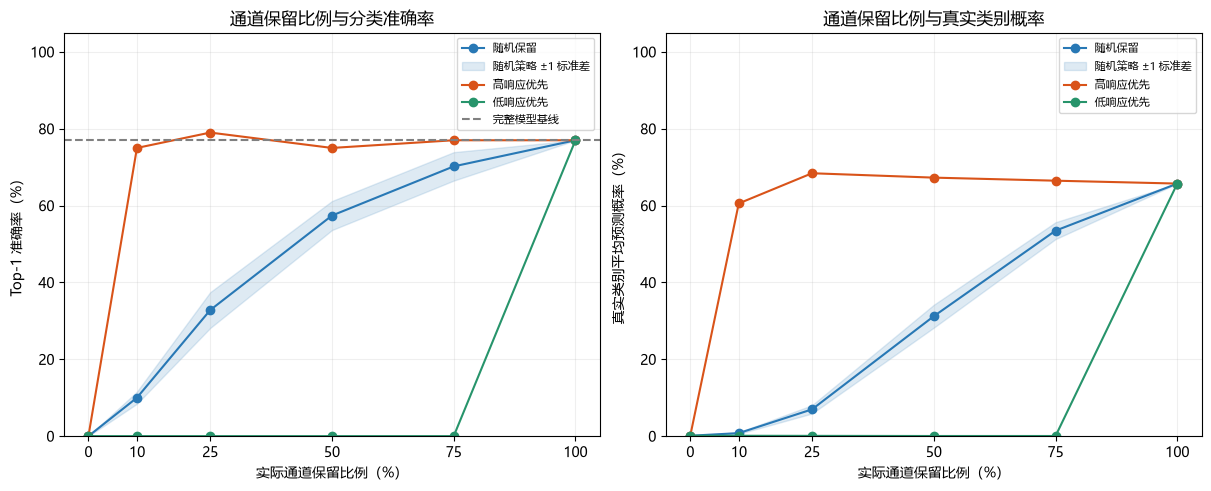

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
colors = {"随机保留": "#2878b5", "高响应优先": "#d95319", "低响应优先": "#27946b"}
for strategy in strategies:
    part = curve_df[curve_df["strategy"] == strategy].sort_values("keep_ratio")
    x = part["keep_ratio"].to_numpy() * 100
    for ax, mean_column, std_column in [
        (axes[0], "accuracy_mean", "accuracy_std"),
        (axes[1], "probability_mean", "probability_std"),
    ]:
        y = part[mean_column].to_numpy() * 100
        error = part[std_column].to_numpy() * 100
        ax.plot(x, y, marker="o", color=colors[strategy], label=strategy)
        if strategy == "随机保留":
            ax.fill_between(x, np.clip(y - error, 0, 100), np.clip(y + error, 0, 100),
                            color=colors[strategy], alpha=0.15, label="随机策略 ±1 标准差")
axes[0].axhline(baseline_accuracy * 100, color="gray", linestyle="--", label="完整模型基线")
axes[0].set_title("通道保留比例与分类准确率")
axes[0].set_ylabel("Top-1 准确率（%）")
axes[1].set_title("通道保留比例与真实类别概率")
axes[1].set_ylabel("真实类别平均预测概率（%）")
for ax in axes:
    ax.set_xlabel("实际通道保留比例（%）")
    ax.set_ylim(0, 105)
    ax.set_xticks([0, 10, 25, 50, 75, 100])
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig(RESULT_DIR / "channel_performance.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. 高低响应通道与分类贡献

以金鱼为例，展示响应最高和最低的各 4 个通道，低响应组包含零激活通道。所有通道使用共同颜色范围，便于直接比较原始强度。

响应高不一定代表对金鱼类别的正贡献。对当前目标层，单通道对金鱼 logit 的贡献等于“池化激活 × 金鱼类别全连接权重”，也正好等于单独屏蔽该通道造成的 logit 降低量。下面计算所有通道的贡献，并核对高低响应组的实际屏蔽结果。负贡献通道被屏蔽时，金鱼 logit 反而提高。

这里的贡献仅针对当前图片的金鱼 logit，不等同于对所有类别、预测概率或整个数据集的重要性。

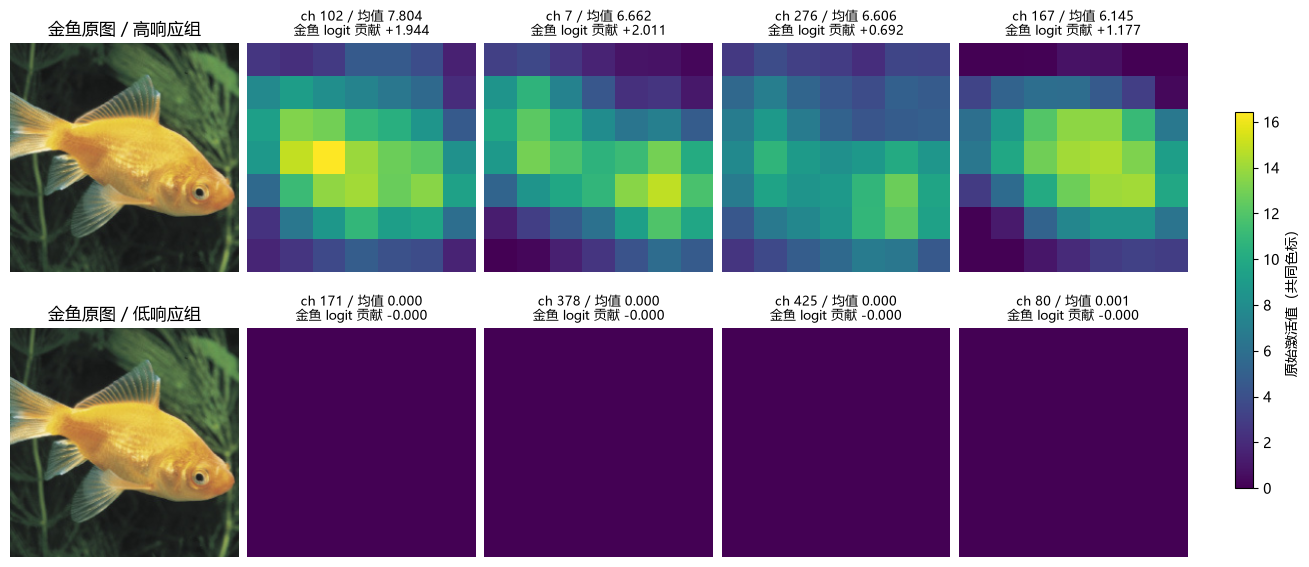

In [6]:
assert selected_ids[0] == 1
example_label = labels[0].item()
response = pooled[0].detach().cpu().numpy()
class_weights = model.fc.weight[example_label].detach().cpu().numpy()
contribution = response * class_weights
feature_maps = example_feature[0].detach().cpu().numpy()
high_ids = np.argsort(-response, kind="stable")[:4]
low_ids = np.argsort(response, kind="stable")[:4]

with torch.no_grad():
    for channel_id in np.concatenate([high_ids, low_ids]):
        masked = pooled[:1].clone()
        masked[:, int(channel_id)] = 0
        drop = (baseline_logits[0, example_label] - model.fc(masked)[0, example_label]).item()
        assert np.isclose(drop, contribution[channel_id], atol=1e-5)

pd.DataFrame({"channel": np.arange(CHANNELS), "mean_response": response,
              "class_weight": class_weights, "goldfish_logit_contribution": contribution}).to_csv(
    RESULT_DIR / "goldfish_channel_contributions.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(2, 5, figsize=(13, 5.7), constrained_layout=True)
shared_max = float(feature_maps[np.concatenate([high_ids, low_ids])].max())
for row, (group, ids) in enumerate([("高响应", high_ids), ("低响应", low_ids)]):
    axes[row, 0].imshow(example_original)
    axes[row, 0].set_title(f"金鱼原图 / {group}组")
    axes[row, 0].axis("off")
    for col, channel_id in enumerate(ids, start=1):
        im = axes[row, col].imshow(feature_maps[channel_id], cmap="viridis",
                                    vmin=0, vmax=shared_max, interpolation="nearest")
        axes[row, col].set_title(
            f"ch {channel_id} / 均值 {response[channel_id]:.3f}\n"
            f"金鱼 logit 贡献 {contribution[channel_id]:+.3f}", fontsize=9)
        axes[row, col].axis("off")
fig.colorbar(im, ax=axes[:, 1:].ravel().tolist(), shrink=0.7, label="原始激活值（共同色标）")
fig.savefig(RESULT_DIR / "high_low_channel_features.png", dpi=180, bbox_inches="tight")
plt.show()

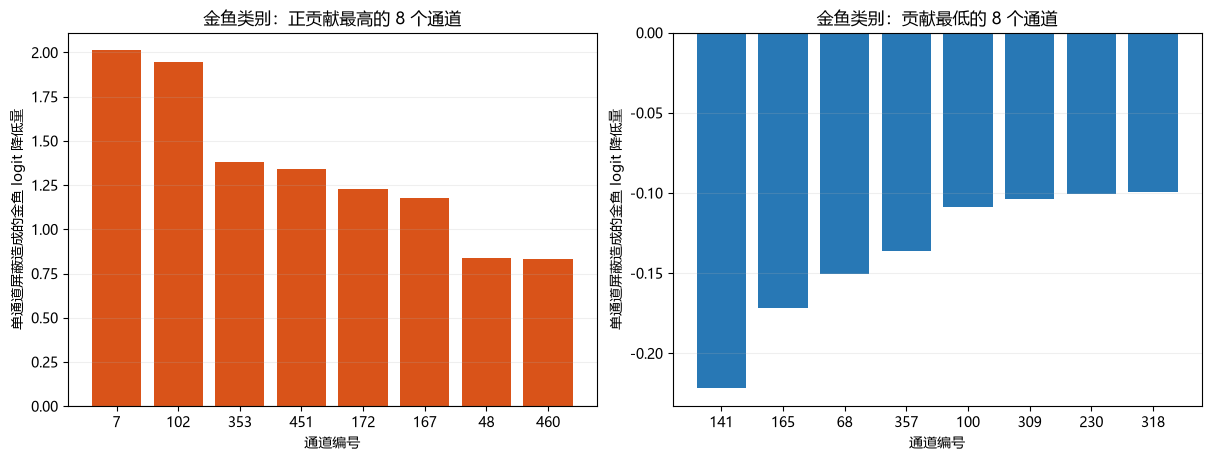

结果已保存至： E:\CODE\DeepLearning-exp\exp3\results\exp3C
屏蔽后的容错表现不能直接证明模型可以无损剪枝；结论仅限当前样本和目标层。


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, ids, title, color in [
    (axes[0], np.argsort(-contribution)[:8], "金鱼类别：正贡献最高的 8 个通道", "#d95319"),
    (axes[1], np.argsort(contribution)[:8], "金鱼类别：贡献最低的 8 个通道", "#2878b5"),
]:
    ax.bar(np.arange(len(ids)), contribution[ids], color=color)
    ax.set_xticks(np.arange(len(ids)), [str(i) for i in ids])
    ax.set_xlabel("通道编号")
    ax.set_ylabel("单通道屏蔽造成的金鱼 logit 降低量")
    ax.set_title(title)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.grid(axis="y", alpha=0.2)
fig.savefig(RESULT_DIR / "channel_contributions.png", dpi=180, bbox_inches="tight")
plt.show()
print("结果已保存至：", RESULT_DIR)
print("屏蔽后的容错表现不能直接证明模型可以无损剪枝；结论仅限当前样本和目标层。")